# BÀI 5: GOM CỤM KHỐI U BẰNG THUẬT TOÁN K-MEANS


## Import thư viện

In [1]:
print("NguyenDucTinh - 6451071077")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    confusion_matrix,
    classification_report
)

from sklearn.metrics.cluster import contingency_matrix
from scipy.optimize import linear_sum_assignment

from sklearn.decomposition import PCA

NguyenDucTinh - 6451071077


## Đọc dữ liệu

In [2]:
print("NguyenDucTinh - 6451071077")

# Đường dẫn đến file dữ liệu
file_path = r'D:\6451071077_Lab23\breast+cancer+wisconsin+diagnostic\wdbc.data'

# Đặt tên cho các cột
columns = ['ID', 'diagnosis']

for i in range(1, 31):
    columns.append('feature_' + str(i))

# Đọc dữ liệu
df = pd.read_csv(
    file_path,
    header=None,
    names=columns
)

# Hiển thị 5 dòng dữ liệu đầu tiên
print("5 dòng dữ liệu đầu tiên:")
display(df.head())

# Hiển thị kích thước dữ liệu
print("\nKích thước dữ liệu:", df.shape)

NguyenDucTinh - 6451071077
5 dòng dữ liệu đầu tiên:


,ID,diagnosis,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,...,feature_21,feature_22,feature_23,feature_24,feature_25,feature_26,feature_27,feature_28,feature_29,feature_30
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Kích thước dữ liệu: (569, 32)


## Khảo sát dữ liệu

NguyenDucTinh - 6451071077
Thông tin dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   ID          569 non-null    int64  
 1   diagnosis   569 non-null    str    
 2   feature_1   569 non-null    float64
 3   feature_2   569 non-null    float64
 4   feature_3   569 non-null    float64
 5   feature_4   569 non-null    float64
 6   feature_5   569 non-null    float64
 7   feature_6   569 non-null    float64
 8   feature_7   569 non-null    float64
 9   feature_8   569 non-null    float64
 10  feature_9   569 non-null    float64
 11  feature_10  569 non-null    float64
 12  feature_11  569 non-null    float64
 13  feature_12  569 non-null    float64
 14  feature_13  569 non-null    float64
 15  feature_14  569 non-null    float64
 16  feature_15  569 non-null    float64
 17  feature_16  569 non-null    float64
 18  feature_17  569 non-null    float64

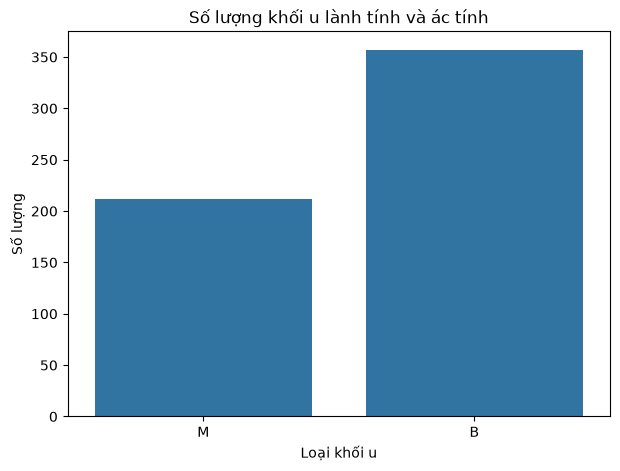

In [3]:
print("NguyenDucTinh - 6451071077")

# Kiểm tra thông tin dữ liệu
print("Thông tin dữ liệu:")
print(df.info())

# Kiểm tra giá trị bị thiếu
print("\nSố lượng giá trị bị thiếu:")
print(df.isnull().sum().sum())

# Thống kê số lượng từng loại khối u
print("\nSố lượng từng loại khối u:")
print(df['diagnosis'].value_counts())

# Hiển thị biểu đồ số lượng khối u
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='diagnosis'
)

plt.title('Số lượng khối u lành tính và ác tính')
plt.xlabel('Loại khối u')
plt.ylabel('Số lượng')

plt.show()

## Tiền xử lý dữ liệu

In [4]:
print("NguyenDucTinh - 6451071077")

# Lưu nhãn thực tế
y_true = df['diagnosis']

# Lấy 30 thuộc tính đặc trưng
X = df.drop(
    columns=['ID', 'diagnosis']
)

# Kiểm tra dữ liệu
print("Kích thước dữ liệu đặc trưng:", X.shape)

print("\nKích thước nhãn:", y_true.shape)

print("\nCác nhãn phân loại:")
print(y_true.unique())

NguyenDucTinh - 6451071077
Kích thước dữ liệu đặc trưng: (569, 30)

Kích thước nhãn: (569,)

Các nhãn phân loại:
<StringArray>
['M', 'B']
Length: 2, dtype: str


## Chuẩn hóa dữ liệu

In [5]:
print("NguyenDucTinh - 6451071077")

# Khởi tạo bộ chuẩn hóa
scaler = StandardScaler()

# Chuẩn hóa dữ liệu
X_scaled = scaler.fit_transform(X)

# Hiển thị kích thước dữ liệu sau chuẩn hóa
print("Kích thước dữ liệu sau chuẩn hóa:", X_scaled.shape)

print("\n5 dòng dữ liệu sau chuẩn hóa:")
print(X_scaled[:5])

NguyenDucTinh - 6451071077
Kích thước dữ liệu sau chuẩn hóa: (569, 30)

5 dòng dữ liệu sau chuẩn hóa:
[[ 1.09706398e+00 -2.07333501e+00  1.26993369e+00  9.84374905e-01
   1.56846633e+00  3.28351467e+00  2.65287398e+00  2.53247522e+00
   2.21751501e+00  2.25574689e+00  2.48973393e+00 -5.65265059e-01
   2.83303087e+00  2.48757756e+00 -2.14001647e-01  1.31686157e+00
   7.24026158e-01  6.60819941e-01  1.14875667e+00  9.07083081e-01
   1.88668963e+00 -1.35929347e+00  2.30360062e+00  2.00123749e+00
   1.30768627e+00  2.61666502e+00  2.10952635e+00  2.29607613e+00
   2.75062224e+00  1.93701461e+00]
 [ 1.82982061e+00 -3.53632408e-01  1.68595471e+00  1.90870825e+00
  -8.26962447e-01 -4.87071673e-01 -2.38458552e-02  5.48144156e-01
   1.39236330e-03 -8.68652457e-01  4.99254601e-01 -8.76243603e-01
   2.63326966e-01  7.42401948e-01 -6.05350847e-01 -6.92926270e-01
  -4.40780058e-01  2.60162067e-01 -8.05450380e-01 -9.94437403e-02
   1.80592744e+00 -3.69203222e-01  1.53512599e+00  1.89048899e+00
  -3.

## Xây dựng mô hình K-Means

In [6]:
print("NguyenDucTinh - 6451071077")

# Khởi tạo mô hình K-Means
kmeans = KMeans(
    n_clusters=2,
    init='k-means++',
    n_init=10,
    max_iter=300,
    random_state=42
)

# Huấn luyện mô hình
kmeans.fit(X_scaled)

# Lấy nhãn cụm
y_cluster = kmeans.labels_

# Hiển thị kết quả
print("Đã hoàn thành gom cụm bằng K-Means")

print("\nSố cụm:", kmeans.n_clusters)

print("Kích thước tâm cụm:", kmeans.cluster_centers_.shape)

print("Giá trị Inertia:", kmeans.inertia_)

print("\nSố lượng mẫu trong từng cụm:")

for i in range(2):
    print(
        "Cụm", i, ":",
        np.sum(y_cluster == i),
        "mẫu"
    )

NguyenDucTinh - 6451071077
Đã hoàn thành gom cụm bằng K-Means

Số cụm: 2
Kích thước tâm cụm: (2, 30)
Giá trị Inertia: 11595.526607115784

Số lượng mẫu trong từng cụm:
Cụm 0 : 375 mẫu
Cụm 1 : 194 mẫu


## So sánh kết quả gom cụm với nhãn thực tế

In [7]:
print("NguyenDucTinh - 6451071077")

# Tạo ma trận phân bố giữa nhãn thực tế và cụm
contingency = contingency_matrix(
    y_true,
    y_cluster
)

print("Ma trận phân bố nhãn thực tế và nhãn cụm:")
print(contingency)

# Tìm cách ánh xạ cụm với nhãn thực tế tối ưu
row_ind, col_ind = linear_sum_assignment(-contingency)

# Lấy danh sách nhãn thực tế
classes = np.unique(y_true)

# Tạo bảng ánh xạ cụm sang nhãn
cluster_to_label = {}

for row, col in zip(row_ind, col_ind):
    cluster_to_label[col] = classes[row]

print("\nBảng ánh xạ cụm sang nhãn thực tế:")

for cluster in sorted(cluster_to_label):
    print(
        "Cụm", cluster,
        "-> Nhãn", cluster_to_label[cluster]
    )

# Chuyển nhãn cụm thành nhãn dự đoán
y_pred = np.array([
    cluster_to_label[cluster]
    for cluster in y_cluster
])

print("\n10 nhãn thực tế đầu tiên:")
print(y_true.iloc[:10].values)

print("\n10 nhãn dự đoán đầu tiên:")
print(y_pred[:10])

NguyenDucTinh - 6451071077
Ma trận phân bố nhãn thực tế và nhãn cụm:
[[339  18]
 [ 36 176]]

Bảng ánh xạ cụm sang nhãn thực tế:
Cụm 0 -> Nhãn B
Cụm 1 -> Nhãn M

10 nhãn thực tế đầu tiên:
<StringArray>
['M', 'M', 'M', 'M', 'M', 'M', 'M', 'M', 'M', 'M']
Length: 10, dtype: str

10 nhãn dự đoán đầu tiên:
['M' 'M' 'M' 'M' 'M' 'M' 'M' 'M' 'M' 'M']


## Đánh giá kết quả gom cụm

In [8]:
print("NguyenDucTinh - 6451071077")

# Tính độ chính xác
accuracy = accuracy_score(y_true, y_pred)

# Tính Adjusted Rand Index
ari = adjusted_rand_score(y_true, y_cluster)

# Tính Normalized Mutual Information
nmi = normalized_mutual_info_score(y_true, y_cluster)

# Hiển thị kết quả
print("KẾT QUẢ ĐÁNH GIÁ K-MEANS")

print("Accuracy:", round(accuracy, 4))

print("ARI:", round(ari, 4))

print("NMI:", round(nmi, 4))

# Báo cáo phân loại
print("\nBáo cáo phân loại:")

print(
    classification_report(
        y_true,
        y_pred,
        labels=['B', 'M'],
        target_names=['Benign', 'Malignant'],
        zero_division=0
    )
)

NguyenDucTinh - 6451071077
KẾT QUẢ ĐÁNH GIÁ K-MEANS
Accuracy: 0.9051
ARI: 0.6536
NMI: 0.5324

Báo cáo phân loại:
              precision    recall  f1-score   support

      Benign       0.90      0.95      0.93       357
   Malignant       0.91      0.83      0.87       212

    accuracy                           0.91       569
   macro avg       0.91      0.89      0.90       569
weighted avg       0.91      0.91      0.90       569



## Trực quan hóa ma trận nhầm lẫn

NguyenDucTinh - 6451071077


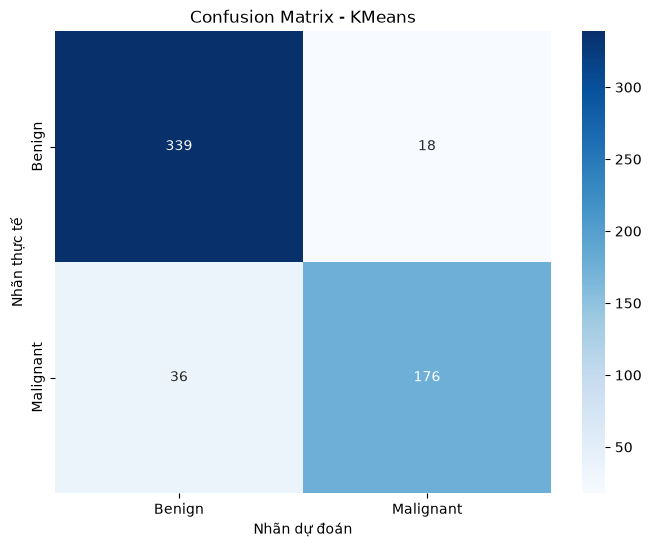

In [9]:
print("NguyenDucTinh - 6451071077")

# Tạo ma trận nhầm lẫn
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=['B', 'M']
)

# Vẽ biểu đồ
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.title('Confusion Matrix - KMeans')
plt.xlabel('Nhãn dự đoán')
plt.ylabel('Nhãn thực tế')

plt.show()

## Trực quan hóa kết quả gom cụm bằng PCA

NguyenDucTinh - 6451071077


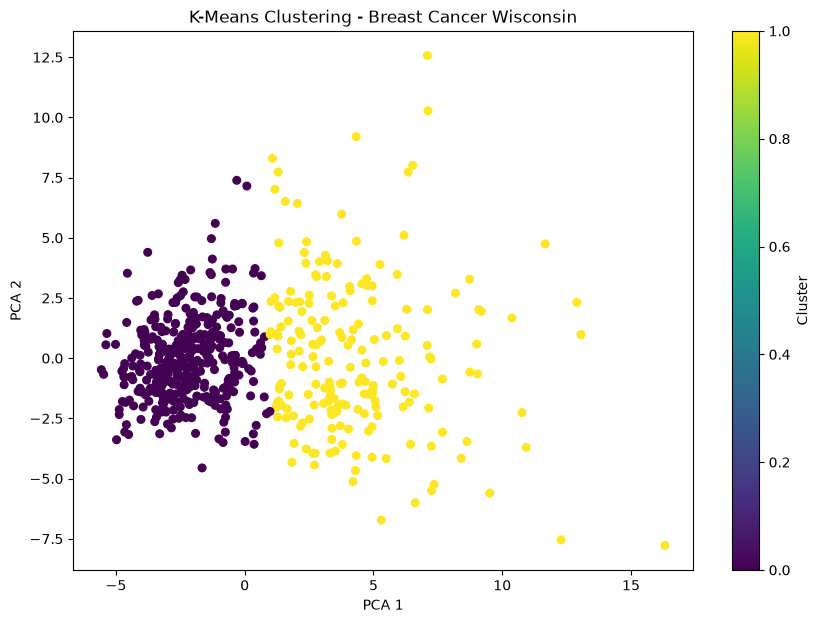

In [10]:
print("NguyenDucTinh - 6451071077")

# Khởi tạo PCA với 2 thành phần
pca = PCA(n_components=2)

# Giảm số chiều dữ liệu
X_pca = pca.fit_transform(X_scaled)

# Hiển thị kết quả gom cụm
plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y_cluster,
    cmap='viridis',
    s=30
)

plt.title('K-Means Clustering - Breast Cancer Wisconsin')

plt.xlabel('PCA 1')
plt.ylabel('PCA 2')

plt.colorbar(label='Cluster')

plt.show()

## So sánh nhãn thực tế và kết quả gom cụm

NguyenDucTinh - 6451071077


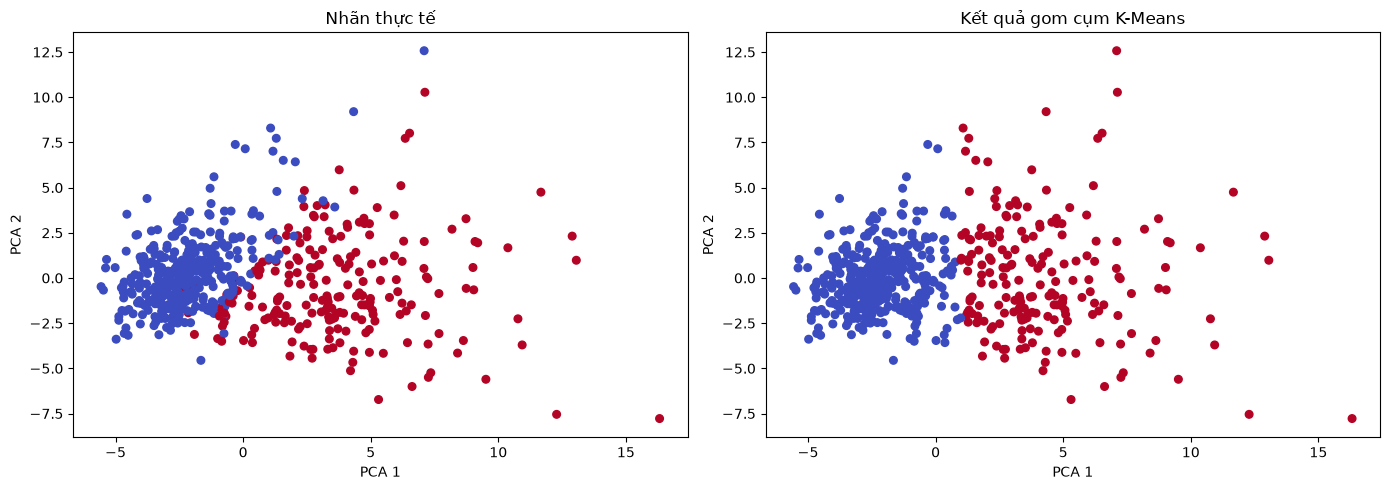

In [11]:
print("NguyenDucTinh - 6451071077")

# Tạo biểu đồ gồm 2 phần
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ nhãn thực tế
ax[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=pd.Series(y_true).map({'B': 0, 'M': 1}),
    cmap='coolwarm',
    s=30
)

ax[0].set_title('Nhãn thực tế')
ax[0].set_xlabel('PCA 1')
ax[0].set_ylabel('PCA 2')

# Biểu đồ nhãn gom cụm
ax[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y_pred.astype(str) == 'M',
    cmap='coolwarm',
    s=30
)

ax[1].set_title('Kết quả gom cụm K-Means')
ax[1].set_xlabel('PCA 1')
ax[1].set_ylabel('PCA 2')

plt.tight_layout()
plt.show()